In [6]:
import torch
from torchvision import datasets, transforms
from torch.utils import data
from torch import nn
import matplotlib.pyplot as plt

In [7]:
def data_maker():
    trans=transforms.ToTensor()
    train_dataset=datasets.FashionMNIST(root='../data',train=True,transform=trans,download=True)
    test_dataset=datasets.FashionMNIST(root='../data',train=False,transform=trans,download=True)
    return train_dataset,test_dataset

In [8]:
def data_loader(data_maker,batch_size,shuffle1):
    return data.DataLoader(data_maker,batch_size,shuffle=shuffle1)

In [9]:
net=nn.Sequential(nn.Flatten(),nn.Linear(784,10))

with torch.no_grad():
    net[1].weight.normal_(0,0.01)
    net[1].bias.fill_(0)

loss=nn.CrossEntropyLoss()

trainer=torch.optim.SGD(net.parameters(),lr=0.1)

epoch=20
batch_size=256

train_dataset,test_dataset=data_maker()
train_iter=data_loader(train_dataset,batch_size,True)
test_iter=data_loader(test_dataset,batch_size,False)



In [10]:
for i in range(epoch):
    train_loss_sum=0.0
    train_correct=0
    train_count=0
    net.train()
    
    for x,y in train_iter:
        logit=net(x)
        l=loss(logit,y)
        trainer.zero_grad()
        l.backward()
        trainer.step()
        train_loss_sum+=l.item()*y.shape[0]
        train_correct+=(logit.argmax(dim=1)==y).sum().item()
        train_count+=y.shape[0]
    train_loss=train_loss_sum/train_count
    train_accuracy=train_correct/train_count
    net.eval()
    
    test_loss_sum=0.0
    test_correct=0
    test_count=0
    with torch.no_grad():
        for x,y in test_iter:
            logit=net(x)
            l=loss(logit,y)
            test_loss_sum+=l.item()*y.shape[0]
            test_correct+=(logit.argmax(dim=1)==y).sum().item()
            test_count+=y.shape[0]
    test_loss=test_loss_sum/test_count
    test_accuracy=test_correct/test_count

    print(f'trainloss:{train_loss:.5f},trainacc:{train_accuracy:.5f}')
    print(f'testloss:{test_loss:.5f},testacc:{test_accuracy:.5f}')


trainloss:0.78616,trainacc:0.74937
testloss:0.62955,testacc:0.79120
trainloss:0.57017,trainacc:0.81325
testloss:0.57298,testacc:0.80240
trainloss:0.52572,trainacc:0.82563
testloss:0.54611,testacc:0.81150
trainloss:0.50172,trainacc:0.83168
testloss:0.54537,testacc:0.80480
trainloss:0.48635,trainacc:0.83723
testloss:0.50573,testacc:0.82730
trainloss:0.47431,trainacc:0.83968
testloss:0.50093,testacc:0.82770
trainloss:0.46507,trainacc:0.84263
testloss:0.49216,testacc:0.83060
trainloss:0.45883,trainacc:0.84457
testloss:0.49197,testacc:0.83120
trainloss:0.45224,trainacc:0.84668
testloss:0.50285,testacc:0.82000
trainloss:0.44736,trainacc:0.84813
testloss:0.47708,testacc:0.83400
trainloss:0.44353,trainacc:0.84857
testloss:0.48729,testacc:0.83230
trainloss:0.43943,trainacc:0.85053
testloss:0.49444,testacc:0.82920
trainloss:0.43537,trainacc:0.85123
testloss:0.47047,testacc:0.83750
trainloss:0.43322,trainacc:0.85265
testloss:0.46910,testacc:0.83560
trainloss:0.43033,trainacc:0.85327
testloss:0.46

In [11]:
X,Y=next(iter(train_iter))
logit=net(X)
print(logit.shape)
print(logit.size())

torch.Size([256, 10])
torch.Size([256, 10])


torch.Size([256, 1, 28, 28])
torch.Size([1, 28, 28])
3


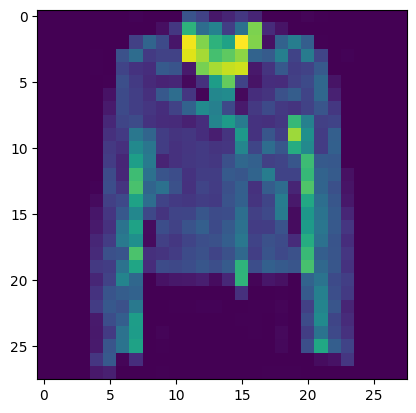

In [12]:
X, y = next(iter(train_iter))
print(X.size())

# 取一张图片
image = X[0]
print(X[0].size())
print(X[0].dim())

# 显示灰度图
plt.imshow(image.squeeze())

# 显示
plt.show()